In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# LSWMD.pkl 원본 쪼개기

In [ ]:
import pandas as pd

path = '/content/drive/MyDrive/_for_exercise/LSWMD.pkl'
df = pd.read_pickle(path)

print(df.shape)
print(df.columns)
df.head()

In [ ]:
# 본인의 경로로 수정

!cp '/content/drive/MyDrive/_for_exercise/LSWMD.pkl' "/content/LSWMD.pkl"


In [ ]:
df = pd.read_pickle('/content/LSWMD.pkl')

In [ ]:
# 전체 데이터 섞어서 20등분
import numpy as np

df_shuffled = df.sample(frac=1, random_state=42).reset_index(drop=True)
parts = np.array_split(df_shuffled, 20)

In [ ]:
# 전체 데이터 섞어서 20등분 -> 파일로 저장
import os
import numpy as np

# 원본 DataFrame 이름이 df라고 가정
num_parts = 20

save_dir = '/content/drive/MyDrive/_for_exercise/WM811K_split_lec'
os.makedirs(save_dir, exist_ok=True)

# DataFrame을 행 기준으로 거의 균등하게 분할
parts = np.array_split(df, num_parts)

for i, part in enumerate(parts, start=1):
    filename = f'LSWMD_{i:02d}.pkl'
    path = os.path.join(save_dir, filename)

    part.to_pickle(path)

    print(f'{filename} 저장 완료: {part.shape}')

In [ ]:
import gc
import pandas as pd

# 1. 기존 큰 DataFrame 제거
del df
gc.collect()

# 2. 분할 파일 읽기
df = pd.read_pickle(
    '/content/drive/MyDrive/_for_exercise/WM811K_split/LSWMD_01.pkl'
)

# 3. 결과 확인
print(df.shape)
df.head()

# 본격 탐색 작업
* 탐색의 목적 : 어떻게 수업 실습용 subset을 만들 것인지 결정하기 위해서

## 1. 전체 DataFrame 파악하기

In [ ]:
import pandas as pd

path = '/content/drive/MyDrive/_for_exercise/WM811K_split/LSWMD_01.pkl'

df = pd.read_pickle(path)

print(df.shape)
print(df.columns)
print(df.head())
print(df.sample(10))

(40573, 6)
Index(['waferMap', 'dieSize', 'lotName', 'waferIndex', 'trianTestLabel',
       'failureType'],
      dtype='object')
                                            waferMap  dieSize lotName  \
0  [[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...   1683.0    lot1   
1  [[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...   1683.0    lot1   
2  [[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...   1683.0    lot1   
3  [[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...   1683.0    lot1   
4  [[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...   1683.0    lot1   

   waferIndex trianTestLabel failureType  
0         1.0   [[Training]]    [[none]]  
1         2.0   [[Training]]    [[none]]  
2         3.0   [[Training]]    [[none]]  
3         4.0   [[Training]]    [[none]]  
4         5.0   [[Training]]    [[none]]  
                                                waferMap  dieSize  lotName  \
25462  [[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1,...    939.0  lot2779   
37656  [[0, 0, 0, 

In [ ]:
# colum 이름에 오타 수정 : trianTestLabel -> trainTestLabel
cols = [
    'waferMap',
    'dieSize',
    'lotName',
    'waferIndex',
    'trainTestLabel',
    'failureType'
]

df.columns = cols
df.head()

,waferMap,dieSize,lotName,waferIndex,trainTestLabel,failureType
0,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,1.0,[[Training]],[[none]]
1,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,2.0,[[Training]],[[none]]
2,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,3.0,[[Training]],[[none]]
3,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,4.0,[[Training]],[[none]]
4,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,5.0,[[Training]],[[none]]


In [ ]:
# 각 컬럼의 정보 조회하기 : 데이터 타입, 실제 값 샘플
print(df.columns)
print()

for col in df.columns:
    print(f'[{col}]')
    print('type:', type(df[col].iloc[0]))
    print('sample:', df[col].iloc[0])
    print('-' * 50)

Index(['waferMap', 'dieSize', 'lotName', 'waferIndex', 'trainTestLabel',
       'failureType'],
      dtype='object')

[waferMap]
type: <class 'numpy.ndarray'>
sample: [[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]
--------------------------------------------------
[dieSize]
type: <class 'numpy.float64'>
sample: 1683.0
--------------------------------------------------
[lotName]
type: <class 'numpy.str_'>
sample: lot1
--------------------------------------------------
[waferIndex]
type: <class 'numpy.float64'>
sample: 1.0
--------------------------------------------------
[trainTestLabel]
type: <class 'numpy.ndarray'>
sample: [['Training']]
--------------------------------------------------
[failureType]
type: <class 'numpy.ndarray'>
sample: [['none']]
--------------------------------------------------


## 2. 각 컬럼별로 하나씩 데이터 파악하기

In [ ]:
# waferMap 데이터 파악하기
sample = df['waferMap'].iloc[0]

print(type(sample))
print(sample.shape)
print(sample.dtype)
print(sample)

<class 'numpy.ndarray'>
(45, 48)
uint8
[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]


In [ ]:
import numpy as np

# waferMap 데이터가 어떤 값으로 구성되어있는지
np.unique(sample)

array([0, 1, 2], dtype=uint8)

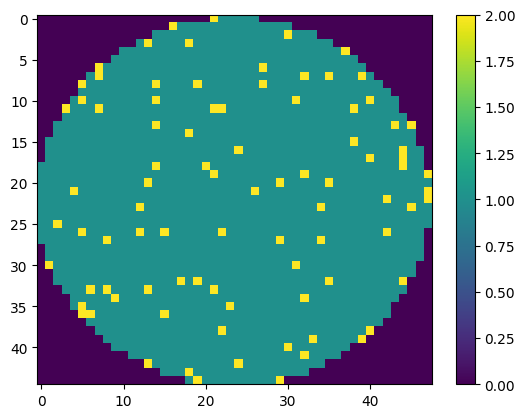

In [ ]:
import matplotlib.pyplot as plt

plt.imshow(sample)
plt.colorbar()
plt.show()

In [ ]:
# dieSize 파악하기
print(df['dieSize'].head())
print("-"*50)
print(df['dieSize'].describe())

0    1683.0
1    1683.0
2    1683.0
3    1683.0
4    1683.0
Name: dieSize, dtype: float64
--------------------------------------------------
count    40573.000000
mean      1440.941094
std       1832.744961
min         12.000000
25%        710.000000
50%        741.000000
75%       1075.000000
max      21338.000000
Name: dieSize, dtype: float64


In [ ]:
# lotName 파악하기
print(df['lotName'].head())
print(df['lotName'].nunique())


0    lot1
1    lot1
2    lot1
3    lot1
4    lot1
Name: lotName, dtype: object
2487


In [ ]:
# waferIndex 파악하기
print(df['waferIndex'].head())

df['waferIndex'].value_counts()


In [ ]:
# trianTestLabel 파악하기

# 바로 value_counts 하면 오래 걸림.
# 평탄화 작업이 필요함.
# df['trianTestLabel'].value_counts(dropna=False) # 이 코드는 실행하지 말 것

In [ ]:
# trainTestLabel의 값은 2차원 리스트에 들어있음
# 2차원 리스트에서 값을 꺼내서 train_label 변수에 저장
train_label = df['trainTestLabel'].apply(
    lambda x: x[0][0] if len(x) > 0 else None
)

# train_label의 value_counts
train_label.value_counts(dropna=False)

# 원본 df가 변경된 것은 아님

,count
trainTestLabel,
None,32180
Training,8393


In [ ]:
# failure_type 파악하기

# failure_type의 값은 2차원 리스트에 들어있음
# 2차원 리스트에서 값을 꺼내서 failure_type 변수에 저장
failure_type = df['failureType'].apply(
    lambda x: x[0][0] if len(x) > 0 else None
)
# failure_type의 value_counts
failure_type.value_counts(dropna=False)

# 마찬가지로 원본 df가 변경된 것은 아님

,count
failureType,
None,32180
none,6383
Edge-Ring,1370
Edge-Loc,228
Random,165
Loc,130
Scratch,54
Donut,30
Center,25


## 이중 리스트 형태의 데이터를 평탄화해서 원본 df에 저장

In [ ]:
# extract_label() : 평탄화 작업을 하는 함수 정의
# 빈 배열이 섞여 있을 수 있어서, 이 방법이 조금 더 안전함.
def extract_label(x):
    try:
        return x[0][0]
    except:
        return None


In [ ]:
# apply로 trainTestLabel과 failureType에 extract_label() 일괄 적용함
train_label = df['trainTestLabel'].apply(extract_label)
failure_type = df['failureType'].apply(extract_label)

# 결과 확인
print(train_label.value_counts(dropna=False))
print("-"*50)
print(failure_type.value_counts(dropna=False))

trainTestLabel
None        32180
Training     8393
Name: count, dtype: int64
--------------------------------------------------
failureType
None         32180
none          6383
Edge-Ring     1370
Edge-Loc       228
Random         165
Loc            130
Scratch         54
Donut           30
Center          25
Near-full        8
Name: count, dtype: int64


In [ ]:
# 평탄화 한 값을 원본에 새 컬럼으로 붙이기
df['trainLabel_clean'] = df['trainTestLabel'].apply(extract_label)
df['failureType_clean'] = df['failureType'].apply(extract_label)


In [ ]:
# 결과 확인
df.head()

,waferMap,dieSize,lotName,waferIndex,trainTestLabel,failureType,trainLabel_clean,failureType_clean,waferShape
0,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,1.0,[[Training]],[[none]],Training,none,"(45, 48)"
1,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,2.0,[[Training]],[[none]],Training,none,"(45, 48)"
2,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,3.0,[[Training]],[[none]],Training,none,"(45, 48)"
3,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,4.0,[[Training]],[[none]],Training,none,"(45, 48)"
4,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,5.0,[[Training]],[[none]],Training,none,"(45, 48)"


In [ ]:
df.sample(10)

,waferMap,dieSize,lotName,waferIndex,trainTestLabel,failureType,trainLabel_clean,failureType_clean
2878,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 2, 2, 1, 2,...",533.0,lot116,12.0,[[Training]],[[none]],Training,none
27519,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",924.0,lot2914,6.0,[],[],None,None
31550,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",776.0,lot3102,1.0,[],[],None,None
33699,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 2,...",741.0,lot3209,8.0,[],[],None,None
6963,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1,...",533.0,lot280,16.0,[[Training]],[[none]],Training,none
27959,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1,...",741.0,lot2933,25.0,[],[],None,None
23769,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",6065.0,lot2669,21.0,[],[],None,None
18681,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 1, 1,...",741.0,lot2402,2.0,[],[],None,None
22555,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",7874.0,lot2568,6.0,[],[],None,None
27238,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 1, 1,...",1063.0,lot2902,10.0,[],[],None,None


## 웨이퍼맵의 크기, 클래스별 웨이퍼맵의 분포

### 1. 웨이퍼맵 크기가 얼마나 다양한지

In [ ]:
# 1. 웨이퍼맵 크기가 얼마나 다양한지
# 먼저 shape를 뽑아보자.

df['waferShape'] = df['waferMap'].apply(lambda x: x.shape)

df['waferShape'].value_counts().head(20)

,count
waferShape,
"(33, 29)",10366
"(26, 26)",7655
"(30, 34)",3783
"(40, 40)",1867
"(32, 29)",1434
"(34, 34)",1365
"(38, 36)",1134
"(34, 35)",1098
"(39, 31)",1066


In [ ]:
# 웨이퍼맵 크기 전체 종류 수
df['waferShape'].nunique()

162

### 2. dieSize와 실제 waferMap 크기의 관계

In [ ]:
# 2. dieSize와 실제 waferMap 크기의 관계

df[['dieSize', 'waferShape']].head(20)

,dieSize,waferShape
0,1683.0,"(45, 48)"
1,1683.0,"(45, 48)"
2,1683.0,"(45, 48)"
3,1683.0,"(45, 48)"
4,1683.0,"(45, 48)"
5,1683.0,"(45, 48)"
6,1683.0,"(45, 48)"
7,1683.0,"(45, 48)"
8,1683.0,"(45, 48)"
9,1683.0,"(45, 48)"


In [ ]:
df[['dieSize', 'waferShape']].sample(20)

,dieSize,waferShape
24686,741.0,"(33, 29)"
7056,533.0,"(26, 26)"
14175,3927.0,"(69, 73)"
40327,8065.0,"(114, 90)"
3279,533.0,"(26, 26)"
23712,6065.0,"(87, 89)"
13937,741.0,"(33, 29)"
32025,7874.0,"(118, 84)"
28487,741.0,"(33, 29)"
32781,736.0,"(31, 31)"


In [ ]:
# 같은 dieSize인데 shape가 같은지 다른지
df.groupby('dieSize')['waferShape'].nunique().sort_values(ascending=False).head(20)

,waferShape
dieSize,
2963.0,3
2801.0,2
712.0,2
723.0,2
838.0,2
1254.0,2
2954.0,2
924.0,2
2972.0,2


In [ ]:
sample = df['waferMap'].iloc[0]

print('dieSize:', df['dieSize'].iloc[0])
print('0이 아닌 픽셀 수:', (sample != 0).sum())

dieSize: 1683.0
0이 아닌 픽셀 수: 1683


### 3. 클래스별 웨이퍼 몇 장 직접 보기

In [ ]:
# 3. 클래스별 웨이퍼 몇 장 직접 보기

# 라벨이 있는 데이터만 선택
labeled = df[df['failureType_clean'].notna()]


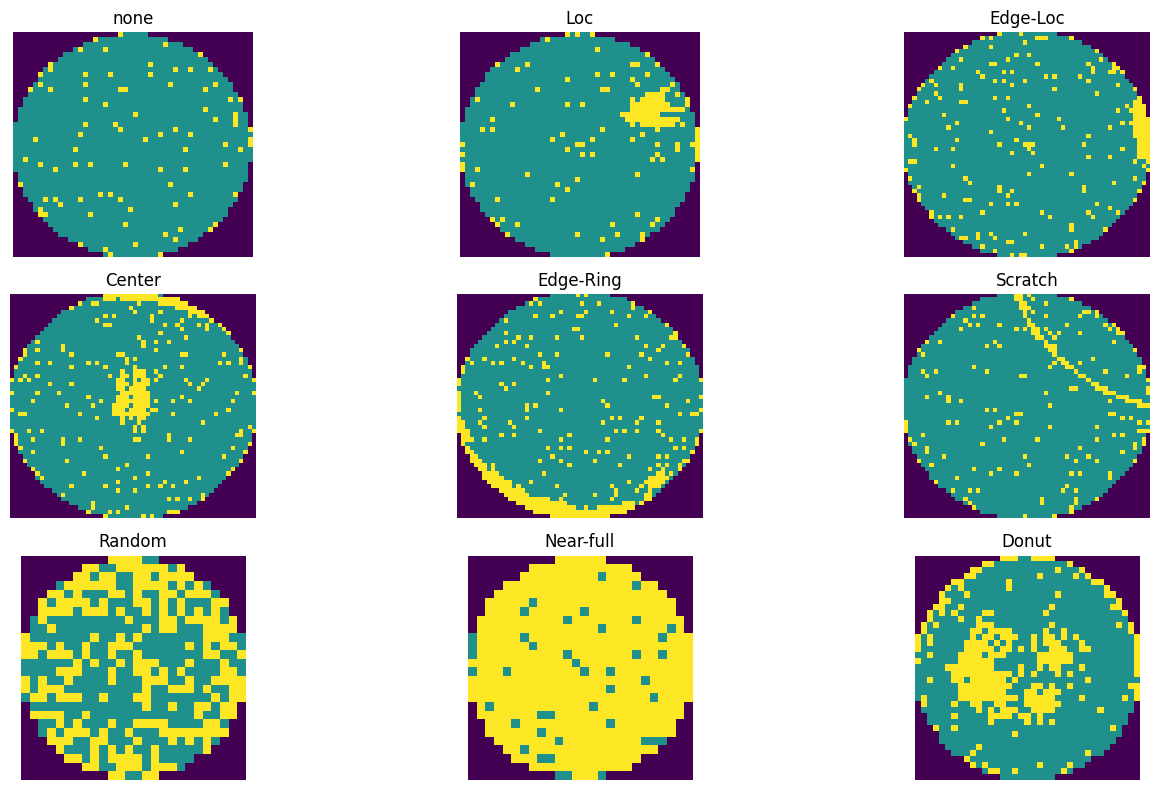

In [ ]:
import matplotlib.pyplot as plt

classes = labeled['failureType_clean'].unique()

plt.figure(figsize=(15, 8))

for i, cls in enumerate(classes):
    sample = labeled[labeled['failureType_clean'] == cls].iloc[0]

    plt.subplot(3, 3, i + 1)
    plt.imshow(sample['waferMap'])
    plt.title(cls)
    plt.axis('off')

plt.tight_layout()
plt.show()

### 4. 이미지 크기별로 failure class 분포 확인

In [ ]:
labeled.head()

,waferMap,dieSize,lotName,waferIndex,trainTestLabel,failureType,trainLabel_clean,failureType_clean,waferShape
0,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,1.0,[[Training]],[[none]],Training,none,"(45, 48)"
1,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,2.0,[[Training]],[[none]],Training,none,"(45, 48)"
2,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,3.0,[[Training]],[[none]],Training,none,"(45, 48)"
3,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,4.0,[[Training]],[[none]],Training,none,"(45, 48)"
4,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,5.0,[[Training]],[[none]],Training,none,"(45, 48)"


In [ ]:
labeled.groupby('waferShape').size().head()

,0
waferShape,
"(25, 27)",7
"(26, 25)",2
"(26, 26)",6283
"(26, 30)",1
"(29, 29)",15


In [ ]:
labeled.groupby('waferShape').size().sort_values(ascending=False).head(10)

,0
waferShape,
"(26, 26)",6283
"(38, 36)",1000
"(41, 41)",139
"(53, 58)",121
"(63, 62)",118
"(69, 73)",113
"(33, 29)",61
"(50, 43)",46
"(37, 37)",42


In [ ]:
labeled.groupby('failureType_clean').size()

,0
failureType_clean,
Center,25
Donut,30
Edge-Loc,228
Edge-Ring,1370
Loc,130
Near-full,8
Random,165
Scratch,54
none,6383


In [ ]:
labeled.groupby(['waferShape', 'failureType_clean']).size()

waferShape  failureType_clean
(25, 27)    Edge-Loc              7
(26, 25)    Edge-Loc              1
            Edge-Ring             1
(26, 26)    Center               12
            Edge-Loc             88
                                 ..
(113, 71)   Random                3
            Scratch               1
(118, 84)   Edge-Loc              1
            Loc                   2
            Scratch               5
Length: 120, dtype: int64

In [ ]:
grouped = labeled.groupby(['waferShape', 'failureType_clean']).size()

In [ ]:
grouped.unstack(fill_value=0)

failureType_clean,Center,Donut,Edge-Loc,Edge-Ring,Loc,Near-full,Random,Scratch,none
waferShape,,,,,,,,,
"(25, 27)",0,0,7,0,0,0,0,0,0
"(26, 25)",0,0,1,1,0,0,0,0,0
"(26, 26)",12,0,88,19,42,8,20,21,6073
"(26, 30)",0,0,0,0,0,0,0,1,0
"(29, 29)",0,0,15,0,0,0,0,0,0
"(29, 30)",0,0,1,0,0,0,8,0,0
"(30, 30)",0,2,1,0,0,0,0,0,0
"(30, 34)",0,0,29,2,3,0,2,1,0
"(32, 29)",0,0,3,1,1,0,1,0,0


In [ ]:
shape_class = labeled.groupby(['waferShape', 'failureType_clean']).size().unstack(fill_value=0)

In [ ]:
shape_class.head(20)

failureType_clean,Center,Donut,Edge-Loc,Edge-Ring,Loc,Near-full,Random,Scratch,none
waferShape,,,,,,,,,
"(25, 27)",0,0,7,0,0,0,0,0,0
"(26, 25)",0,0,1,1,0,0,0,0,0
"(26, 26)",12,0,88,19,42,8,20,21,6073
"(26, 30)",0,0,0,0,0,0,0,1,0
"(29, 29)",0,0,15,0,0,0,0,0,0
"(29, 30)",0,0,1,0,0,0,8,0,0
"(30, 30)",0,2,1,0,0,0,0,0,0
"(30, 34)",0,0,29,2,3,0,2,1,0
"(32, 29)",0,0,3,1,1,0,1,0,0


In [ ]:
shape_class.loc[
    [(33,29), (26,26), (30,34), (40,40), (32,29)]
]

failureType_clean,Center,Donut,Edge-Loc,Edge-Ring,Loc,Near-full,Random,Scratch,none
waferShape,,,,,,,,,
"(33, 29)",0,1,12,38,2,0,2,6,0
"(26, 26)",12,0,88,19,42,8,20,21,6073
"(30, 34)",0,0,29,2,3,0,2,1,0
"(40, 40)",0,0,0,37,0,0,1,0,0
"(32, 29)",0,0,3,1,1,0,1,0,0


In [ ]:
# 각 shape에 존재하는 failureType 종류 수
class_count_by_shape = shape_class.gt(0).sum(axis=1).sort_values(ascending=False)

class_count_by_shape.head(20)

,0
waferShape,
"(26, 26)",8
"(33, 29)",6
"(53, 58)",6
"(30, 34)",5
"(37, 55)",4
"(37, 37)",4
"(32, 29)",4
"(34, 34)",3
"(36, 34)",3


In [ ]:
top_shapes = class_count_by_shape.head(10).index

shape_class.loc[top_shapes]

failureType_clean,Center,Donut,Edge-Loc,Edge-Ring,Loc,Near-full,Random,Scratch,none
waferShape,,,,,,,,,
"(26, 26)",12,0,88,19,42,8,20,21,6073
"(33, 29)",0,1,12,38,2,0,2,6,0
"(53, 58)",2,0,8,1,3,0,0,1,106
"(30, 34)",0,0,29,2,3,0,2,1,0
"(37, 55)",0,8,2,0,1,0,0,0,6
"(37, 37)",11,1,0,0,7,0,0,0,23
"(32, 29)",0,0,3,1,1,0,1,0,0
"(34, 34)",0,0,0,9,2,0,0,1,0
"(36, 34)",0,0,1,0,9,0,0,0,7


## 5. subset 확정하기

In [ ]:
# 전체 데이터셋에서 (26,26) 분포 확인
# 20등분 했던 전체 데이터셋를 순회하면서 (26,26)크기 웨이퍼맵의 failureType 분포를 확인
#
#
import pandas as pd
import os
import gc

all_counts = {}
root_path = '/content/drive/MyDrive/_for_exercise/WM811K_split_lec/'

for i in range(1, 21):
    path = os.path.join(root_path, f'LSWMD_{i:02d}.pkl')
    part = pd.read_pickle(path)

    # failureType 문자열 꺼내기
    part['failureType_clean'] = part['failureType'].apply(
        lambda x: x[0][0] if len(x) > 0 else None
    )

    # (26, 26)만 선택
    selected = part[
        part['waferMap'].apply(lambda x: x.shape == (26, 26))
    ]

    # 클래스별 개수
    counts = selected['failureType_clean'].value_counts(dropna=False)

    for label, count in counts.items():
        all_counts[label] = all_counts.get(label, 0) + count

    del part
    gc.collect()

all_counts

{np.str_('none'): 13489,
 None: 15712,
 np.str_('Edge-Loc'): 296,
 np.str_('Loc'): 297,
 np.str_('Scratch'): 72,
 np.str_('Random'): 74,
 np.str_('Edge-Ring'): 31,
 np.str_('Center'): 90,
 np.str_('Near-full'): 16,
 np.str_('Donut'): 1}

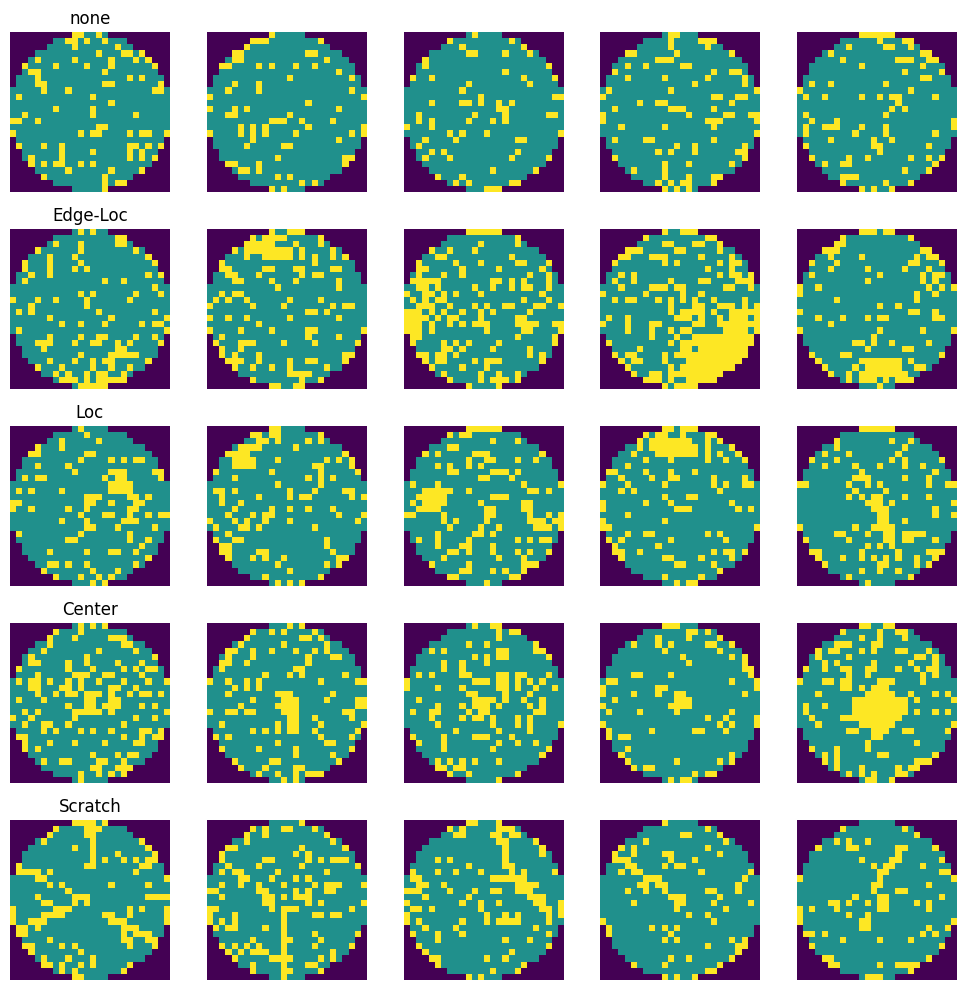

In [ ]:
# (26,26) 데이터맵 중 일부 컬럼 데이터를 5개씩 시각화

classes = ['none', 'Edge-Loc', 'Loc', 'Center', 'Scratch']

fig, axes = plt.subplots(len(classes), 5, figsize=(10, 10))

for row, cls in enumerate(classes):
    samples = labeled[
        (labeled['waferShape'] == (26, 26)) &
        (labeled['failureType_clean'] == cls)
    ].head(5)

    for col, (_, sample) in enumerate(samples.iterrows()):
        axes[row, col].imshow(sample['waferMap'])
        axes[row, col].axis('off')

    axes[row, 0].set_title(cls)

plt.tight_layout()
plt.show()

In [ ]:
# df['failureType_clean'].value_counts()
list(df['failureType_clean'].unique())

[np.str_('none'),
 np.str_('Loc'),
 None,
 np.str_('Edge-Loc'),
 np.str_('Center'),
 np.str_('Edge-Ring'),
 np.str_('Scratch'),
 np.str_('Random'),
 np.str_('Near-full'),
 np.str_('Donut')]

In [ ]:
# 서브셋 만들기

# (26,26) 모으기
import pandas as pd
import os
import gc

# folder = '/content/drive/MyDrive/AI비전실무/WM811K_split'

target_classes = ['none', 'Edge-Loc', 'Loc', 'Center', 'Scratch', 'Edge-Ring', 'Random']
target_shape = (26, 26)

collected = []

for i in range(1, 21):
    path = os.path.join(root_path, f'LSWMD_{i:02d}.pkl')
    part = pd.read_pickle(path)

    # 필요한 라벨만 간단히 정리
    part['failureType_clean'] = part['failureType'].apply(
        lambda x: x[0][0] if len(x) > 0 else None
    )

    # 26x26 + 목표 클래스만 추출
    selected = part[
        (part['waferMap'].apply(lambda x: x.shape == target_shape)) &
        (part['failureType_clean'].isin(target_classes))
    ].copy()

    collected.append(selected)

    print(f'{i:02d}번 파일: {len(selected)}개 확보')

    del part
    gc.collect()


01번 파일: 6275개 확보
02번 파일: 1개 확보
03번 파일: 8개 확보
04번 파일: 5개 확보
05번 파일: 62개 확보
06번 파일: 4개 확보
07번 파일: 2개 확보
08번 파일: 0개 확보
09번 파일: 0개 확보
10번 파일: 2개 확보
11번 파일: 2개 확보
12번 파일: 0개 확보
13번 파일: 0개 확보
14번 파일: 0개 확보
15번 파일: 0개 확보
16번 파일: 6642개 확보
17번 파일: 1346개 확보
18번 파일: 0개 확보
19번 파일: 0개 확보
20번 파일: 0개 확보


In [ ]:
# 모은 데이터 합치기
candidates = pd.concat(collected, ignore_index=True)

print(candidates.shape)
print(candidates['failureType_clean'].value_counts())

(14349, 7)
failureType_clean
none         13489
Loc            297
Edge-Loc       296
Center          90
Random          74
Scratch         72
Edge-Ring       31
Name: count, dtype: int64


In [ ]:
# # 클래스별 60개씩 랜덤 추출
# subset = candidates.groupby('failureType_clean', group_keys=False) \
#                 .sample(n=60, random_state=42).reset_index(drop=True)

In [ ]:
# 클래스끼리 붙어 있지 않도록 한 번 더 섞기
# subset = subset.sample(frac=1, random_state=42).reset_index(drop=True)

In [ ]:
subset = candidates

In [ ]:
# 결과 확인
print(subset.shape)
print(subset['failureType_clean'].value_counts())

(14349, 7)
failureType_clean
none         13489
Loc            297
Edge-Loc       296
Center          90
Random          74
Scratch         72
Edge-Ring       31
Name: count, dtype: int64


In [ ]:
subset.head()

,waferMap,dieSize,lotName,waferIndex,trianTestLabel,failureType,failureType_clean
0,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 2, 1, 1, 2,...",533.0,lot7,1.0,[[Training]],[[none]],none
1,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 1, 1, 1, 1,...",533.0,lot7,2.0,[[Training]],[[none]],none
2,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 2, 1, 1, 1,...",533.0,lot7,3.0,[[Training]],[[none]],none
3,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 2, 2, 1, 1,...",533.0,lot7,4.0,[[Training]],[[none]],none
4,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 2, 2, 2, 2,...",533.0,lot7,5.0,[[Training]],[[none]],none


In [ ]:
# 실습용 데이터셋 추출
subset_student = subset[['waferMap', 'failureType_clean']].rename(columns={'failureType_clean': 'label'})

In [ ]:
subset_student.head()

,waferMap,label
0,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 2, 1, 1, 2,...",none
1,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 1, 1, 1, 1,...",none
2,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 2, 1, 1, 1,...",none
3,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 2, 2, 1, 1,...",none
4,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 2, 2, 2, 2,...",none


In [ ]:
# 데이터셋 저장
# subset_student.to_pickle(root_path + 'WM811K_subset_26x26_4class.pkl')
subset_student.to_pickle('/content/drive/MyDrive/_for_exercise/WM811K_subset_26x26_full.pkl')